# 68 Algorithms Challenge: Journey to Mastery
## K-Nearest Neighbors (scikit-learn implementation)

Author: Tyra Nyambura  
Date: 19th November, 2026  
Goal: Master KNN by applying scikit-learn's KNN to the Wine dataset and comparing it against our from-scratch implementation.

### Why use scikit-learn here?
In Model 05 we built KNN from scratch to understand exactly how distance and voting work under the hood. Now we will use `KNeighborsClassifier` to confirm that the library reproduces our results, and to explore how it handles edge cases like ties and different distance metrics.

### Step 1: Loading our toolkit
We load `numpy`, `pandas`, `matplotlib`, `seaborn`, and `KNeighborsClassifier` from `sklearn.neighbors`.

In [1]:
import matplotlib as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn import datasets

data = datasets.load_wine(as_frame=True)

In [2]:
data

{'data':      alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
 0      14.23        1.71  2.43               15.6      127.0           2.80   
 1      13.20        1.78  2.14               11.2      100.0           2.65   
 2      13.16        2.36  2.67               18.6      101.0           2.80   
 3      14.37        1.95  2.50               16.8      113.0           3.85   
 4      13.24        2.59  2.87               21.0      118.0           2.80   
 ..       ...         ...   ...                ...        ...            ...   
 173    13.71        5.65  2.45               20.5       95.0           1.68   
 174    13.40        3.91  2.48               23.0      102.0           1.80   
 175    13.27        4.28  2.26               20.0      120.0           1.59   
 176    13.17        2.59  2.37               20.0      120.0           1.65   
 177    14.13        4.10  2.74               24.5       96.0           2.05   
 
      flavanoids  nonflavanoid

### Step 2: Data loading & exploration
We load the Wine dataset using `sklearn.datasets.load_wine`, build a DataFrame, and use `sns.pairplot` to visualise the three classes across the feature pairs.

In [3]:
x = data.data
y = data.target
names = data.target_names
print(names)

['class_0' 'class_1' 'class_2']


In [4]:
df = pd.DataFrame(x, columns=data.feature_names)
df["wine class"] = data.target
df["wine class"] = df["wine class"].replace(
    to_replace=[0, 1, 2], value=["class_0", "class_1", "class_2"]
)

In [5]:
df

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,wine class
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,class_0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,class_0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,class_0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,class_0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,class_0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
173,13.71,5.65,2.45,20.5,95.0,1.68,0.61,0.52,1.06,7.70,0.64,1.74,740.0,class_2
174,13.40,3.91,2.48,23.0,102.0,1.80,0.75,0.43,1.41,7.30,0.70,1.56,750.0,class_2
175,13.27,4.28,2.26,20.0,120.0,1.59,0.69,0.43,1.35,10.20,0.59,1.56,835.0,class_2
176,13.17,2.59,2.37,20.0,120.0,1.65,0.68,0.53,1.46,9.30,0.60,1.62,840.0,class_2


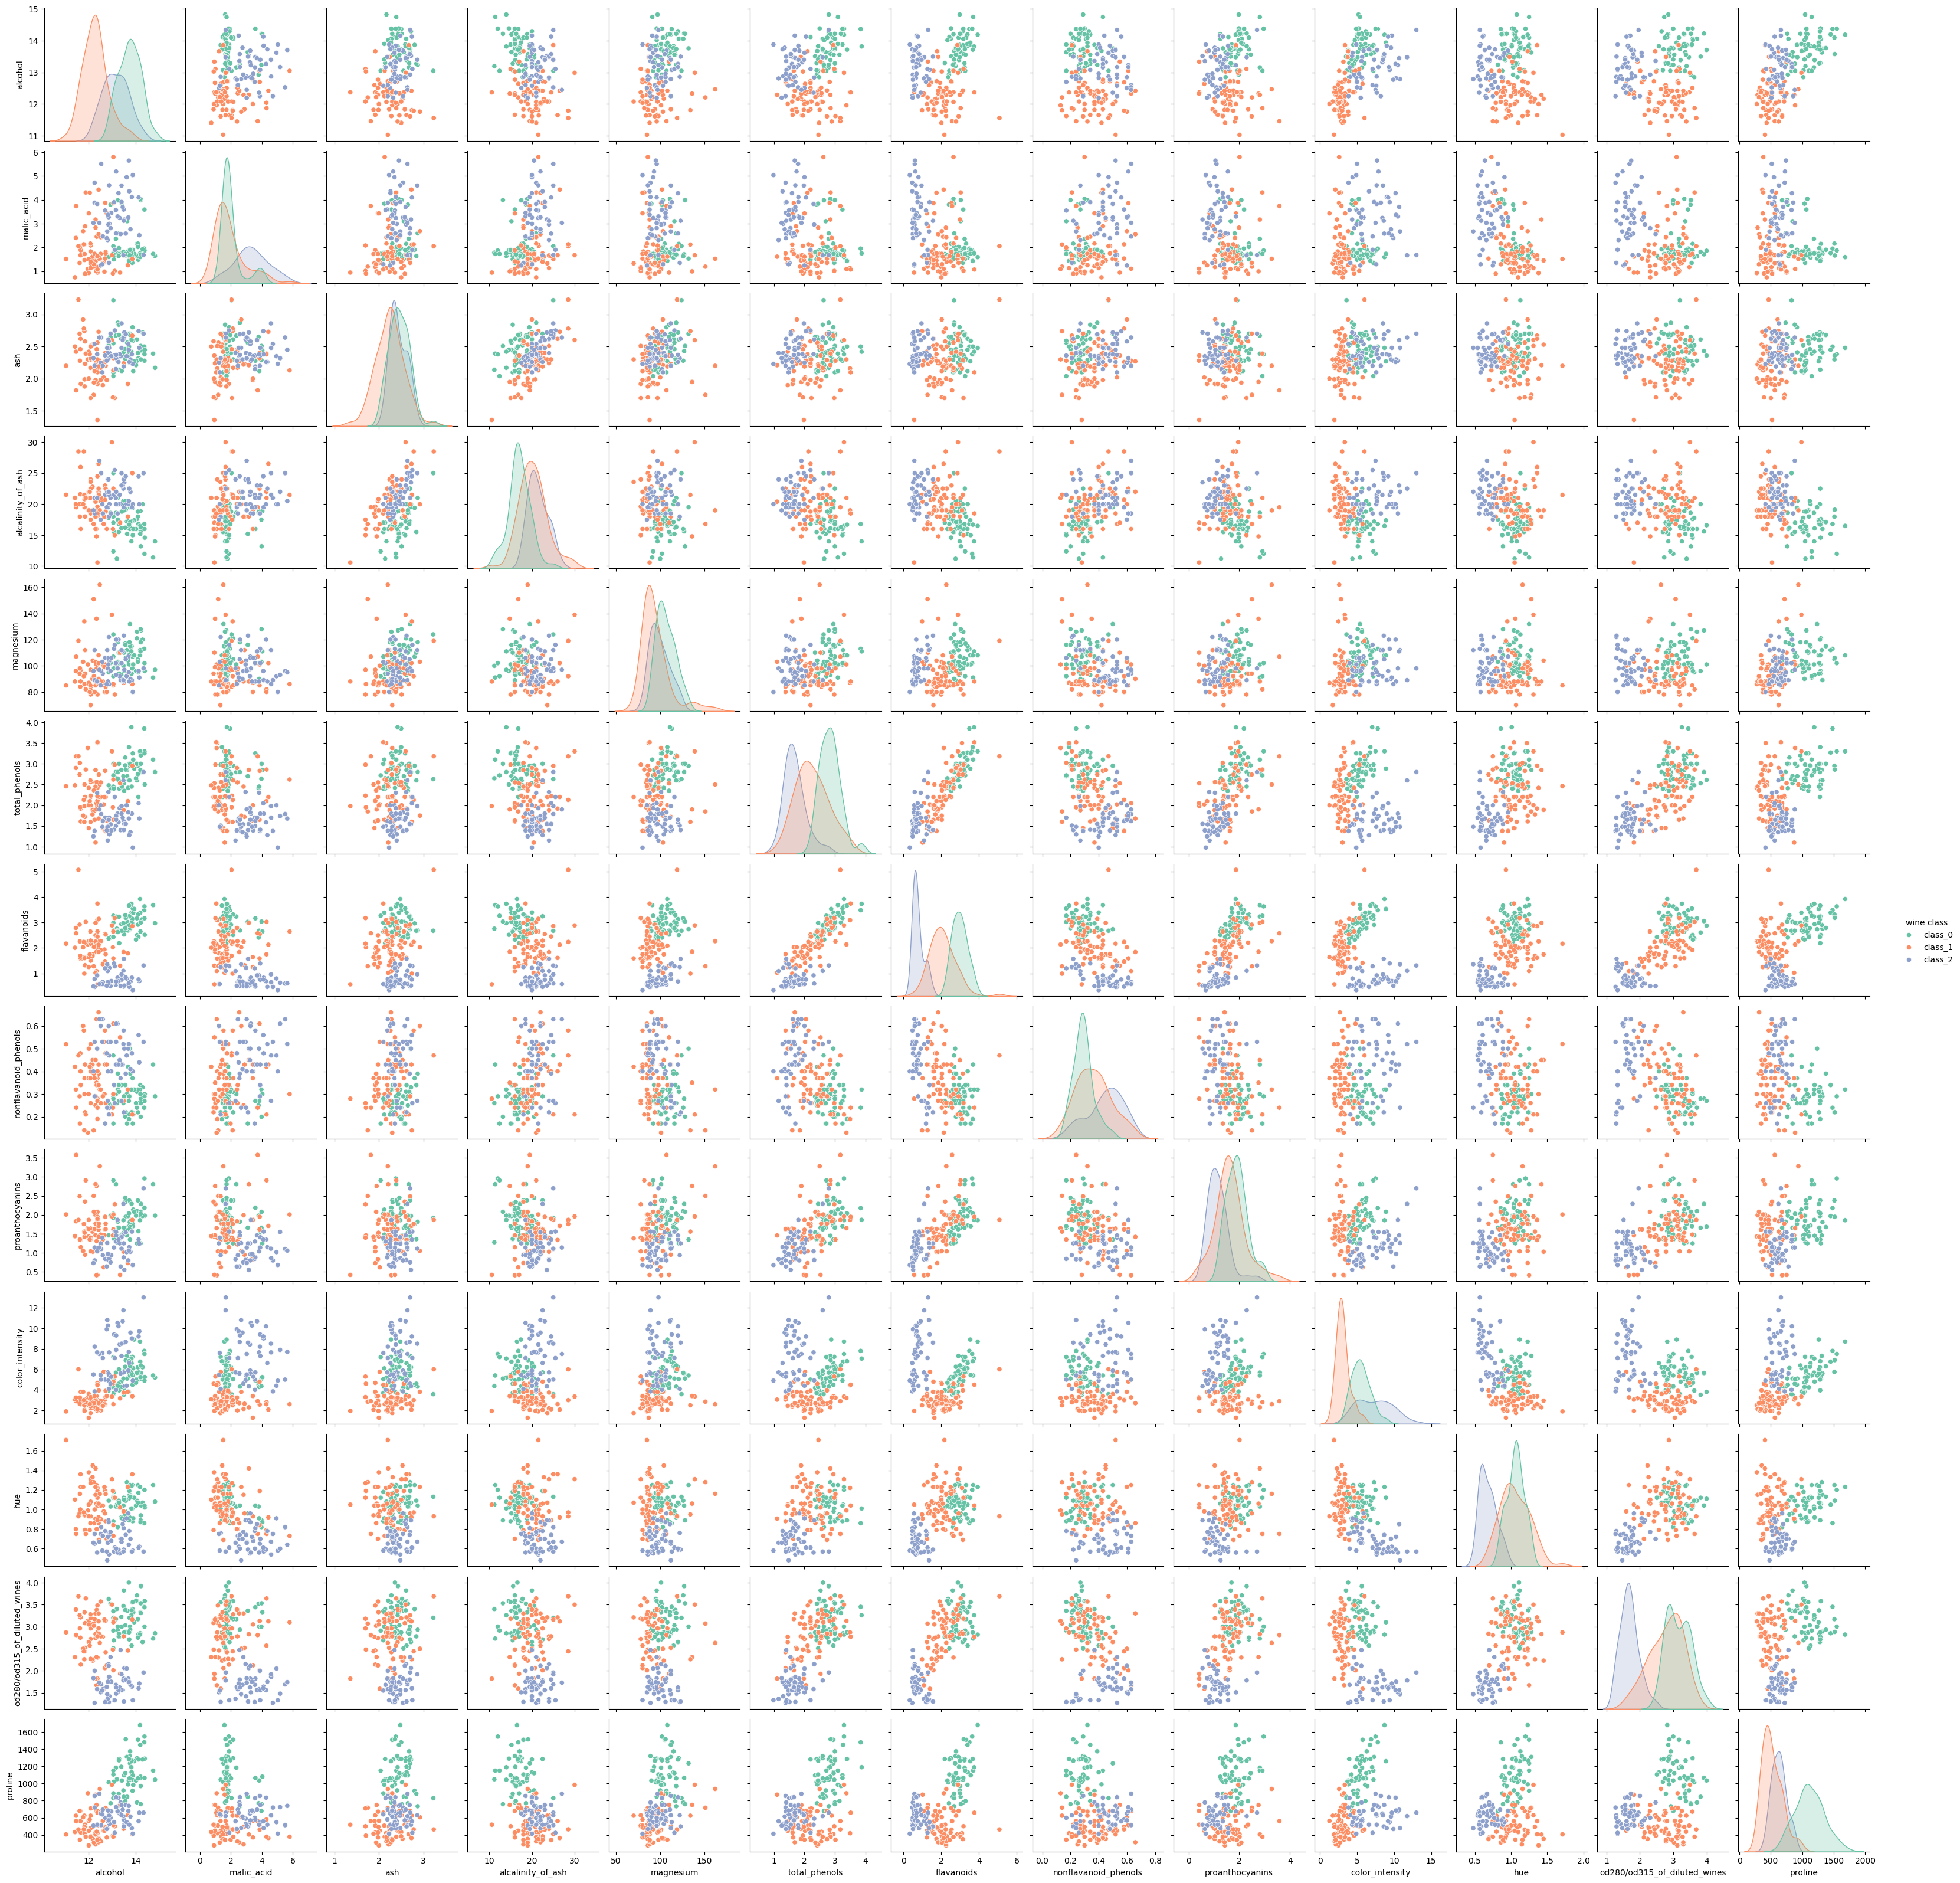

In [6]:
sns.pairplot(data=df, hue="wine class", palette="Set2")

In [7]:
df.isnull().sum()

alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
wine class                      0
dtype: int64

### Step 3: Train/test split
We split the data into train and test sets with a fixed `random_state`. We also compute `sqrt(len(y_test))` as a rule-of-thumb baseline for choosing `k`.

In [8]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=1)

### Step 4: Training the scikit-learn model
We initialise `KNeighborsClassifier(n_neighbors=7)` and fit it on the raw training data.

In [9]:
import math

from sklearn.neighbors import KNeighborsClassifier

math.sqrt(len(y_test))

7.3484692283495345

In [10]:
knn = KNeighborsClassifier(n_neighbors=7)
knn.fit(x_train, y_train)
pred = knn.predict(x_test)

### Step 5: Standardising the features
Because KNN relies on Euclidean distance, we standardise the features with a `StandardScaler` and retrain. This usually improves accuracy since the features are on different scales.

In [11]:
from sklearn import metrics

metrics.accuracy_score(y_test, pred)

0.6481481481481481

In [12]:
df

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,wine class
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,class_0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,class_0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,class_0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,class_0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,class_0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
173,13.71,5.65,2.45,20.5,95.0,1.68,0.61,0.52,1.06,7.70,0.64,1.74,740.0,class_2
174,13.40,3.91,2.48,23.0,102.0,1.80,0.75,0.43,1.41,7.30,0.70,1.56,750.0,class_2
175,13.27,4.28,2.26,20.0,120.0,1.59,0.69,0.43,1.35,10.20,0.59,1.56,835.0,class_2
176,13.17,2.59,2.37,20.0,120.0,1.65,0.68,0.53,1.46,9.30,0.60,1.62,840.0,class_2


### Step 6: Comparing implementations
We evaluate the standardised model and compare its accuracy against the raw model. Both should confirm that KNN works well on this dataset.

In [13]:
from sklearn.preprocessing import StandardScaler

sc = StandardScaler()

x_train = sc.fit_transform(x_train)
x_test = sc.fit_transform(x_test)

In [14]:
knn1 = KNeighborsClassifier(n_neighbors=7, metric="euclidean")
knn1.fit(x_train, y_train)
pred2 = knn1.predict(x_test)

In [15]:
metrics.accuracy_score(y_test, pred2)

0.9814814814814815